Loading Covertype dataset...

Dataset shape:
X: (581012, 54)
y: (581012,)

Number of classes: 7
Classes: [1 2 3 4 5 6 7]

Class Distribution:
Class 1: 211840
Class 2: 283301
Class 3: 35754
Class 4: 2747
Class 5: 9493
Class 6: 17367
Class 7: 20510

Imbalance ratio: 103.13


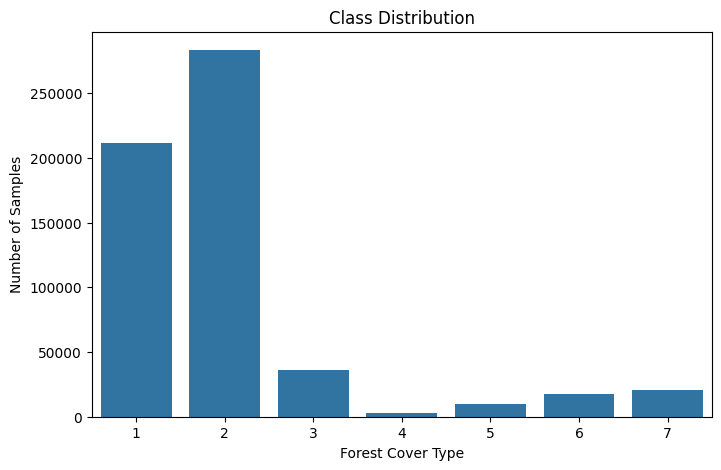


Classes after conversion:
[0 1 2 3 4 5 6]

One-hot encoded target shape:
(581012, 7)

Dataset split:
Training: (464809, 54)
Validation: (58101, 54)
Testing: (58102, 54)

Features standardized.

Class Weights:
Class 0: 0.3918
Class 1: 0.2930
Class 2: 2.3215
Class 3: 30.2099
Class 4: 8.7439
Class 5: 4.7791
Class 6: 4.0469

Starting training...

Epoch 001/100 | Train Loss: 0.6914 | Val Loss: 0.6997 | Train Acc: 0.5829 | Val Acc: 0.5828
Epoch 002/100 | Train Loss: 0.6252 | Val Loss: 0.6291 | Train Acc: 0.6162 | Val Acc: 0.6173
Epoch 003/100 | Train Loss: 0.5844 | Val Loss: 0.5923 | Train Acc: 0.6375 | Val Acc: 0.6383
Epoch 004/100 | Train Loss: 0.5763 | Val Loss: 0.5884 | Train Acc: 0.6821 | Val Acc: 0.6836
Epoch 005/100 | Train Loss: 0.5458 | Val Loss: 0.5588 | Train Acc: 0.6655 | Val Acc: 0.6645
Epoch 006/100 | Train Loss: 0.5251 | Val Loss: 0.5324 | Train Acc: 0.6753 | Val Acc: 0.6763
Epoch 007/100 | Train Loss: 0.5315 | Val Loss: 0.5432 | Train Acc: 0.6769 | Val Acc: 0.6781
Epoch 008/

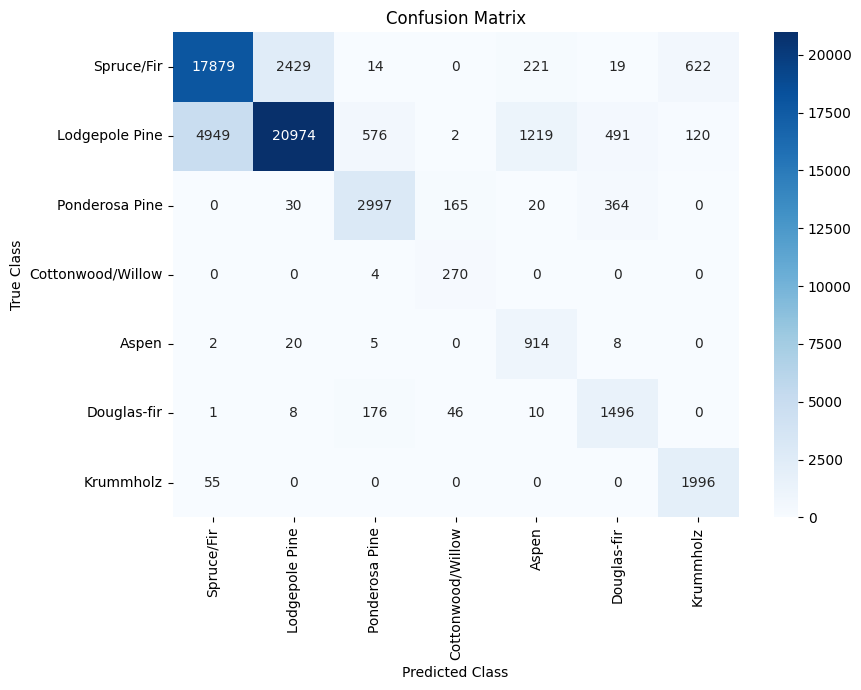

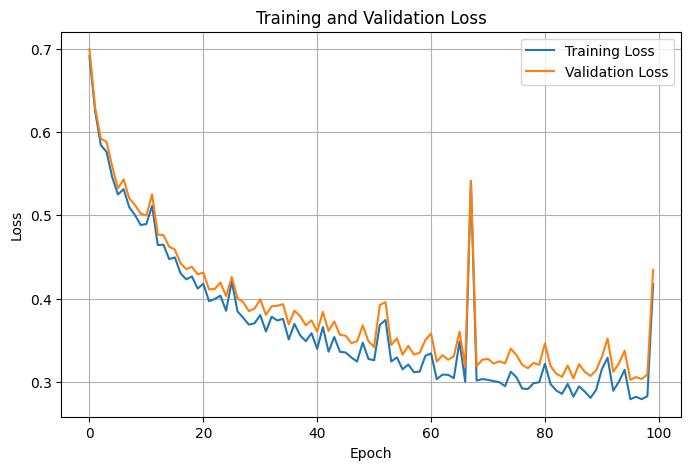

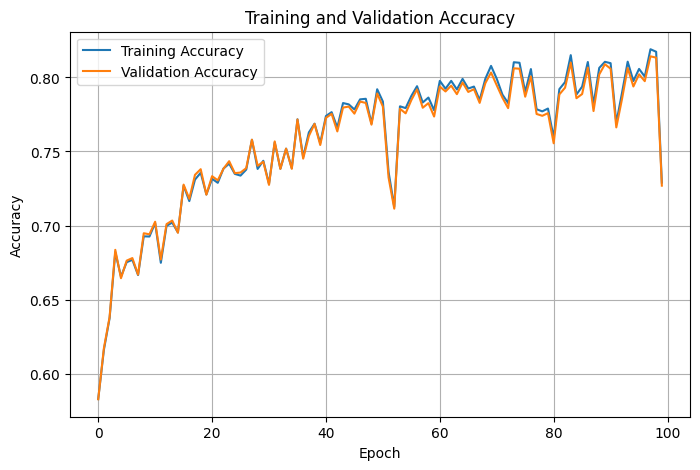

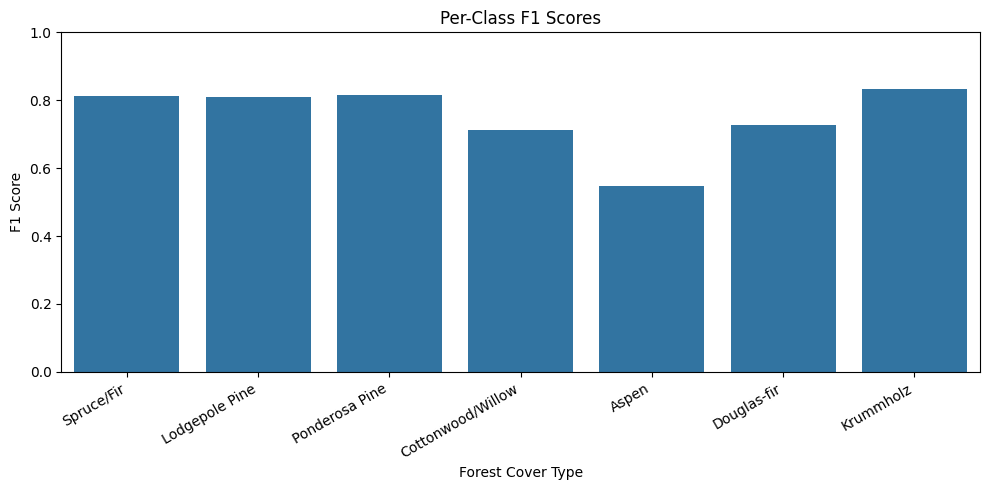

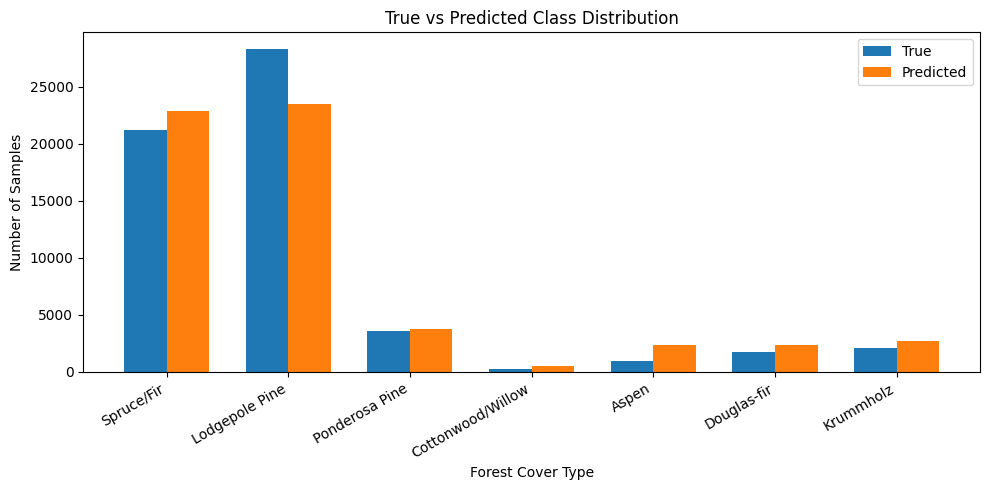


FINAL SUMMARY
Test Accuracy      : 0.8008
Macro Precision    : 0.6815
Macro Recall       : 0.8865
Macro F1 Score     : 0.7514
Epochs Trained     : 100

Network Architecture:
54 -> 64 -> 32 -> 16 -> 7

Activation:
Hidden Layers: ReLU
Output Layer : Softmax

Optimizer:
Mini-Batch SGD

Batch Size:
128

Learning Rate:
0.01

Early Stopping Patience:
15


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


print("Loading Covertype dataset...")

data = fetch_covtype()

X = data.data
y = data.target

print("\nDataset shape:")
print("X:", X.shape)
print("y:", y.shape)

print("\nNumber of classes:", len(np.unique(y)))
print("Classes:", np.unique(y))

# 2. Class Distribution
unique_classes, class_counts = np.unique(y, return_counts=True)

print("\nClass Distribution:")
for c, count in zip(unique_classes, class_counts):
    print(f"Class {c}: {count}")

imbalance_ratio = class_counts.max() / class_counts.min()

print("\nImbalance ratio:",
      round(imbalance_ratio, 2))


plt.figure(figsize=(8, 5))

sns.barplot(
    x=unique_classes,
    y=class_counts
)

plt.title("Class Distribution")
plt.xlabel("Forest Cover Type")
plt.ylabel("Number of Samples")
plt.show()

# 3. Convert Classes 1-7 to 0-6
y = y - 1

print("\nClasses after conversion:")
print(np.unique(y))

# 4. One-Hot Encoding
K = 7

Y = np.eye(K)[y]

print("\nOne-hot encoded target shape:")
print(Y.shape)

# 5. Train / Validation / Test Split
#    80% Train
#    10% Validation
#    10% Test
X_train, X_temp, Y_train, Y_temp, y_train, y_temp = train_test_split(
    X,
    Y,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_val, X_test, Y_val, Y_test, y_val, y_test = train_test_split(
    X_temp,
    Y_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\nDataset split:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

# 6. Standardize Features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("\nFeatures standardized.")

# 7. Calculate Class Weights
#
# wc = N / (K * nc)
N = len(y_train)

train_classes, train_counts = np.unique(
    y_train,
    return_counts=True
)

class_weights = np.zeros(K)

for c, count in zip(train_classes, train_counts):
    class_weights[c] = N / (K * count)

print("\nClass Weights:")

for c in range(K):
    print(
        f"Class {c}: "
        f"{class_weights[c]:.4f}"
    )

# 8. Network Architecture
# Input  : 54
# Hidden1: 64
# Hidden2: 32
# Hidden3: 16
# Output : 7
#
# [54, 64, 32, 16, 7]

input_size = 54
hidden1 = 64
hidden2 = 32
hidden3 = 16
output_size = 7

# 9. He Initialization

np.random.seed(42)

W1 = np.random.randn(
    input_size,
    hidden1
) * np.sqrt(2 / input_size)

b1 = np.zeros((1, hidden1))


W2 = np.random.randn(
    hidden1,
    hidden2
) * np.sqrt(2 / hidden1)

b2 = np.zeros((1, hidden2))


W3 = np.random.randn(
    hidden2,
    hidden3
) * np.sqrt(2 / hidden2)

b3 = np.zeros((1, hidden3))


W4 = np.random.randn(
    hidden3,
    output_size
) * np.sqrt(2 / hidden3)

b4 = np.zeros((1, output_size))

# 10. Activation Functions

def relu(z):
    return np.maximum(0, z)


def relu_derivative(z):
    return (z > 0).astype(float)


def softmax(z):

    # Numerical stability
    z = z - np.max(
        z,
        axis=1,
        keepdims=True
    )

    exp_z = np.exp(z)

    return exp_z / np.sum(
        exp_z,
        axis=1,
        keepdims=True
    )

# 11. Forward Propagation
def forward(X):

    Z1 = X @ W1 + b1
    A1 = relu(Z1)

    Z2 = A1 @ W2 + b2
    A2 = relu(Z2)

    Z3 = A2 @ W3 + b3
    A3 = relu(Z3)

    Z4 = A3 @ W4 + b4

    Y_hat = softmax(Z4)

    cache = (
        X,
        Z1, A1,
        Z2, A2,
        Z3, A3,
        Z4, Y_hat
    )

    return Y_hat, cache

# 12. Weighted Categorical Cross-Entropy
def weighted_cross_entropy(
    Y_true,
    Y_pred,
    weights
):

    # Avoid log(0)
    Y_pred = np.clip(
        Y_pred,
        1e-15,
        1 - 1e-15
    )

    # Weight for true class
    sample_weights = np.sum(
        Y_true * weights,
        axis=1
    )

    loss = -np.mean(
        sample_weights *
        np.sum(
            Y_true * np.log(Y_pred),
            axis=1
        )
    )

    return loss

# 13. Backpropagation

def backward(
    Y_true,
    Y_pred,
    cache,
    weights
):

    global W1, W2, W3, W4

    (
        X,
        Z1, A1,
        Z2, A2,
        Z3, A3,
        Z4, Y_hat
    ) = cache

    B = X.shape[0]
    # Output Layer
    # Softmax + Cross Entropy

    sample_weights = np.sum(
        Y_true * weights,
        axis=1,
        keepdims=True
    )

    dZ4 = (
        (Y_pred - Y_true)
        * sample_weights
    ) / B

    dW4 = A3.T @ dZ4
    db4 = np.sum(
        dZ4,
        axis=0,
        keepdims=True
    )

    # Hidden Layer 3

    dA3 = dZ4 @ W4.T

    dZ3 = (
        dA3 *
        relu_derivative(Z3)
    )

    dW3 = A2.T @ dZ3

    db3 = np.sum(
        dZ3,
        axis=0,
        keepdims=True
    )

    dA2 = dZ3 @ W3.T

    dZ2 = (
        dA2 *
        relu_derivative(Z2)
    )

    dW2 = A1.T @ dZ2

    db2 = np.sum(
        dZ2,
        axis=0,
        keepdims=True
    )
    # Hidden Layer 1

    dA1 = dZ2 @ W2.T

    dZ1 = (
        dA1 *
        relu_derivative(Z1)
    )

    dW1 = X.T @ dZ1

    db1 = np.sum(
        dZ1,
        axis=0,
        keepdims=True
    )
    gradients = (
        dW1, db1,
        dW2, db2,
        dW3, db3,
        dW4, db4
    )

    return gradients

# 14. Hyperparameters
learning_rate = 0.01

batch_size = 128

epochs = 100

patience = 15
# 15. Training History
train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

# 16. Accuracy Function

def calculate_accuracy(
    X,
    Y
):

    predictions, _ = forward(X)

    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    true_classes = np.argmax(
        Y,
        axis=1
    )

    return np.mean(
        predicted_classes ==
        true_classes
    )

# 17. Training - Mini Batch SGD
best_val_loss = np.inf

best_parameters = None

patience_counter = 0

num_samples = X_train.shape[0]


print("\nStarting training...\n")
for epoch in range(epochs):

    # Shuffle training data


    permutation = np.random.permutation(
        num_samples
    )

    X_train_shuffled = X_train[
        permutation
    ]

    Y_train_shuffled = Y_train[
        permutation
    ]
    # Mini-batch training

    for start in range(
        0,
        num_samples,
        batch_size
    ):

        end = min(
            start + batch_size,
            num_samples
        )

        X_batch = X_train_shuffled[
            start:end
        ]

        Y_batch = Y_train_shuffled[
            start:end
        ]

        # Forward propagation

        Y_pred, cache = forward(
            X_batch
        )


        # Backpropagation

        gradients = backward(
            Y_batch,
            Y_pred,
            cache,
            class_weights
        )


        (
            dW1, db1,
            dW2, db2,
            dW3, db3,
            dW4, db4
        ) = gradients

        # Parameter Updates
        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1

        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

        W3 -= learning_rate * dW3
        b3 -= learning_rate * db3

        W4 -= learning_rate * dW4
        b4 -= learning_rate * db4

    # Calculate Training Loss


    train_predictions, _ = forward(
        X_train
    )

    train_loss = weighted_cross_entropy(
        Y_train,
        train_predictions,
        class_weights
    )

    # Validation Loss

    val_predictions, _ = forward(
        X_val
    )

    val_loss = weighted_cross_entropy(
        Y_val,
        val_predictions,
        class_weights
    )
    # Accuracy
    train_accuracy = calculate_accuracy(
        X_train,
        Y_train
    )

    val_accuracy = calculate_accuracy(
        X_val,
        Y_val
    )
    # Store history

    train_losses.append(
        train_loss
    )

    val_losses.append(
        val_loss
    )

    train_accuracies.append(
        train_accuracy
    )

    val_accuracies.append(
        val_accuracy
    )
    print(
        f"Epoch {epoch + 1:03d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )
    # Early Stopping

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        patience_counter = 0

        best_parameters = (
            W1.copy(),
            b1.copy(),
            W2.copy(),
            b2.copy(),
            W3.copy(),
            b3.copy(),
            W4.copy(),
            b4.copy()
        )

    else:

        patience_counter += 1

        if patience_counter >= patience:

            print(
                "\nEarly stopping triggered."
            )

            break

# 18. Restore Best Parameters
if best_parameters is not None:

    (
        W1,
        b1,
        W2,
        b2,
        W3,
        b3,
        W4,
        b4
    ) = best_parameters


print("\nTraining completed.")
# 19. Test Predictions
test_probabilities, _ = forward(
    X_test
)

y_pred = np.argmax(
    test_probabilities,
    axis=1
)

y_true = np.argmax(
    Y_test,
    axis=1
)

# 20. Accuracy
accuracy = accuracy_score(
    y_true,
    y_pred
)
print("\n====================================")
print("TEST RESULTS")
print("====================================")

print(
    f"Accuracy: {accuracy:.4f}"
)
# 21. Precision
precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)
print(
    f"Macro Precision: {precision:.4f}"
)

# 22. Recall
recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print(
    f"Macro Recall: {recall:.4f}"
)
# 23. F1 Score
f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)
print(
    f"Macro F1 Score: {f1:.4f}"
)
# 24. Classification Report
print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Spruce/Fir",
            "Lodgepole Pine",
            "Ponderosa Pine",
            "Cottonwood/Willow",
            "Aspen",
            "Douglas-fir",
            "Krummholz"
        ],
        zero_division=0
    )
)

# 25. Confusion Matrix
cm = confusion_matrix(
    y_true,
    y_pred
)
print("\nConfusion Matrix:\n")
print(cm)
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Spruce/Fir",
        "Lodgepole Pine",
        "Ponderosa Pine",
        "Cottonwood/Willow",
        "Aspen",
        "Douglas-fir",
        "Krummholz"
    ],
    yticklabels=[
        "Spruce/Fir",
        "Lodgepole Pine",
        "Ponderosa Pine",
        "Cottonwood/Willow",
        "Aspen",
        "Douglas-fir",
        "Krummholz"
    ]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.tight_layout()
plt.show()
# 26. Training Loss Curve
plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Training and Validation Loss"
)

plt.legend()

plt.grid(True)

plt.show()

# 27. Training Accuracy Curve
plt.figure(figsize=(8, 5))

plt.plot(
    train_accuracies,
    label="Training Accuracy"
)

plt.plot(
    val_accuracies,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "Training and Validation Accuracy"
)

plt.legend()
plt.grid(True)
plt.show()
# 28. Per-Class F1 Score
class_f1 = f1_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

class_names = [
    "Spruce/Fir",
    "Lodgepole Pine",
    "Ponderosa Pine",
    "Cottonwood/Willow",
    "Aspen",
    "Douglas-fir",
    "Krummholz"
]


plt.figure(figsize=(10, 5))

sns.barplot(
    x=class_names,
    y=class_f1
)

plt.xlabel("Forest Cover Type")
plt.ylabel("F1 Score")

plt.title(
    "Per-Class F1 Scores"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.ylim(0, 1)

plt.tight_layout()

plt.show()

# 29. True vs Predicted Class Distribution
true_counts = np.bincount(
    y_true,
    minlength=K
)

pred_counts = np.bincount(
    y_pred,
    minlength=K
)

x = np.arange(K)

width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    true_counts,
    width,
    label="True"
)

plt.bar(
    x + width / 2,
    pred_counts,
    width,
    label="Predicted"
)

plt.xlabel("Forest Cover Type")
plt.ylabel("Number of Samples")

plt.title(
    "True vs Predicted Class Distribution"
)

plt.xticks(
    x,
    class_names,
    rotation=30,
    ha="right"
)

plt.legend()
plt.tight_layout()
plt.show()
# 30. Final Summary
print("\n====================================")
print("FINAL SUMMARY")
print("====================================")

print(
    f"Test Accuracy      : {accuracy:.4f}"
)

print(
    f"Macro Precision    : {precision:.4f}"
)

print(
    f"Macro Recall       : {recall:.4f}"
)

print(
    f"Macro F1 Score     : {f1:.4f}"
)

print(
    f"Epochs Trained     : {len(train_losses)}"
)

print("\nNetwork Architecture:")
print("54 -> 64 -> 32 -> 16 -> 7")

print("\nActivation:")
print("Hidden Layers: ReLU")
print("Output Layer : Softmax")

print("\nOptimizer:")
print("Mini-Batch SGD")

print("\nBatch Size:")
print(batch_size)

print("\nLearning Rate:")
print(learning_rate)

print("\nEarly Stopping Patience:")
print(patience)